In [1]:
import torch
import torchvision
import timm

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Timm version:", timm.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("CUDA version:", torch.version.cuda)
    print("GPU name:", torch.cuda.get_device_name(0))

    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")

    device = torch.device("cuda")

    x = torch.randn(1000, 1000, device=device)
    y = torch.randn(1000, 1000, device=device)
    z = x @ y

    print("\nGPU computation successful!")
    print("Tensor device:", z.device)
else:
    print("GPU not detected. Check Kaggle accelerator settings.")

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Timm version: 1.0.30

CUDA available: True
CUDA version: 13.0
GPU name: Tesla T4
GPU memory: 14.56 GB

GPU computation successful!
Tensor device: cuda:0


In [2]:
!pip install -q timm scikit-learn seaborn

In [3]:
import os

INPUT_DIR = "/kaggle/input"

print("Available Kaggle datasets:")

for item in os.listdir(INPUT_DIR):
    print("-", item)

Available Kaggle datasets:
- competitions


In [4]:
import glob

csv_files = glob.glob(
    "/kaggle/input/**/train.csv",
    recursive=True
)

print("Training CSV files found:")

for file in csv_files:
    print(file)

Training CSV files found:
/kaggle/input/competitions/paddy-disease-classification/train.csv


In [5]:
import pandas as pd

if len(csv_files) == 0:
    raise FileNotFoundError(
        "train.csv not found. Please attach the Paddy dataset."
    )

CSV_PATH = csv_files[0]

df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nClass distribution:")
print(df["label"].value_counts())

print("\nTotal labelled images:", len(df))

Dataset shape: (10407, 4)

First five records:


,image_id,label,variety,age
0,100330.jpg,bacterial_leaf_blight,ADT45,45
1,100365.jpg,bacterial_leaf_blight,ADT45,45
2,100382.jpg,bacterial_leaf_blight,ADT45,45
3,100632.jpg,bacterial_leaf_blight,ADT45,45
4,101918.jpg,bacterial_leaf_blight,ADT45,45



Column names:
['image_id', 'label', 'variety', 'age']

Class distribution:
label
normal                      1764
blast                       1738
hispa                       1594
dead_heart                  1442
tungro                      1088
brown_spot                   965
downy_mildew                 620
bacterial_leaf_blight        479
bacterial_leaf_streak        380
bacterial_panicle_blight     337
Name: count, dtype: int64

Total labelled images: 10407


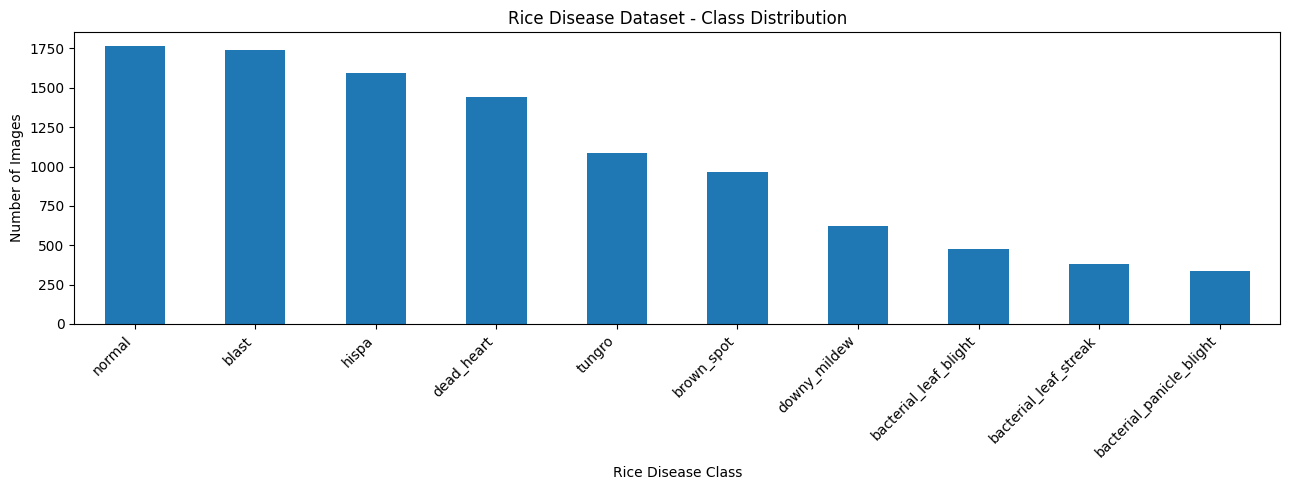

In [6]:
import matplotlib.pyplot as plt

class_counts = df["label"].value_counts()

plt.figure(figsize=(13, 5))

class_counts.plot(kind="bar")

plt.title("Rice Disease Dataset - Class Distribution")
plt.xlabel("Rice Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

After confirming the dataset, we will implement:
- Stratified dataset splitting (70% training, 15% validation, 15% testing).
- Image resizing to 224 × 224.
- Image normalization.
- Training-time augmentation.
- PyTorch Dataset and DataLoader classes.

In [7]:

import os

IMAGE_DIR = "/kaggle/input/competitions/paddy-disease-classification/train_images"

print("TRAIN IMAGES DIRECTORY:")
print(IMAGE_DIR)

print("\nSUBDIRECTORIES:")

for root, dirs, files in os.walk(IMAGE_DIR):
    level = root.replace(IMAGE_DIR, "").count(os.sep)

    if level <= 2:
        print(
            "  " * level,
            os.path.basename(root),
            "| Images/files:", len(files)
        )

        for filename in files[:3]:
            print("  " * (level + 1), filename)


TRAIN IMAGES DIRECTORY:
/kaggle/input/competitions/paddy-disease-classification/train_images

SUBDIRECTORIES:
 train_images | Images/files: 0
   tungro | Images/files: 1088
     109629.jpg
     104765.jpg
     109706.jpg
   hispa | Images/files: 1594
     100502.jpg
     107167.jpg
     106262.jpg
   downy_mildew | Images/files: 620
     101119.jpg
     105381.jpg
     110270.jpg
   bacterial_leaf_streak | Images/files: 380
     103494.jpg
     106019.jpg
     103874.jpg
   bacterial_leaf_blight | Images/files: 479
     109940.jpg
     105979.jpg
     104324.jpg
   brown_spot | Images/files: 965
     104821.jpg
     100229.jpg
     101440.jpg
   blast | Images/files: 1738
     107934.jpg
     108677.jpg
     109170.jpg
   normal | Images/files: 1764
     109776.jpg
     101562.jpg
     106498.jpg
   dead_heart | Images/files: 1442
     109841.jpg
     102631.jpg
     104707.jpg
   bacterial_panicle_blight | Images/files: 337
     107921.jpg
     109434.jpg
     102955.jpg


In [8]:

import os
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

# Reload original CSV because previous validation emptied df
CSV_PATH = (
    "/kaggle/input/competitions/"
    "paddy-disease-classification/train.csv"
)

IMAGE_DIR = Path(
    "/kaggle/input/competitions/"
    "paddy-disease-classification/train_images"
)

df = pd.read_csv(CSV_PATH)

# Standardize image column
if "image_id" in df.columns and "image" not in df.columns:
    df = df.rename(columns={"image_id": "image"})

assert {"image", "label"}.issubset(df.columns)

# Recursively index all images
image_lookup = {}

for path in IMAGE_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in [
        ".jpg", ".jpeg", ".png"
    ]:
        if path.name in image_lookup:
            raise ValueError(
                f"Duplicate filename found: {path.name}"
            )

        image_lookup[path.name] = str(path)

print("Images discovered:", len(image_lookup))

# Map CSV filenames to actual image paths
df["image_path"] = df["image"].astype(str).map(image_lookup)

# Check missing images
missing = df[df["image_path"].isna()]

print("Total CSV records:", len(df))
print("Images found:", df["image_path"].notna().sum())
print("Images missing:", len(missing))

if len(missing) > 0:
    print("\nMissing filename examples:")
    print(missing["image"].head(10).tolist())

# Keep only records with existing image files
df = df.dropna(subset=["image_path"]).reset_index(drop=True)

print("\nFinal dataset size:", len(df))
print("Number of classes:", df["label"].nunique())

display(df.head())


Images discovered: 10407
Total CSV records: 10407
Images found: 10407
Images missing: 0

Final dataset size: 10407
Number of classes: 10


,image,label,variety,age,image_path
0,100330.jpg,bacterial_leaf_blight,ADT45,45,/kaggle/input/competitions/paddy-disease-class...
1,100365.jpg,bacterial_leaf_blight,ADT45,45,/kaggle/input/competitions/paddy-disease-class...
2,100382.jpg,bacterial_leaf_blight,ADT45,45,/kaggle/input/competitions/paddy-disease-class...
3,100632.jpg,bacterial_leaf_blight,ADT45,45,/kaggle/input/competitions/paddy-disease-class...
4,101918.jpg,bacterial_leaf_blight,ADT45,45,/kaggle/input/competitions/paddy-disease-class...


Validate images

In [9]:

from PIL import Image

valid_indices = []
invalid_files = []

for idx, row in tqdm(
    df.iterrows(),
    total=len(df),
    desc="Validating images"
):
    try:
        with Image.open(row["image_path"]) as img:
            img.verify()

        valid_indices.append(idx)

    except Exception:
        invalid_files.append(row["image_path"])

df = df.loc[valid_indices].reset_index(drop=True)

print("\nIMAGE VALIDATION RESULTS")
print("-----------------------")
print("Valid images:", len(df))
print("Invalid images:", len(invalid_files))
print("Disease classes:", df["label"].nunique())

print("\nClass distribution:")
display(df["label"].value_counts().to_frame("Image count"))


Validating images:   0%|          | 0/10407 [00:00<?, ?it/s]


IMAGE VALIDATION RESULTS
-----------------------
Valid images: 10407
Invalid images: 0
Disease classes: 10

Class distribution:


,Image count
label,
normal,1764
blast,1738
hispa,1594
dead_heart,1442
tungro,1088
brown_spot,965
downy_mildew,620
bacterial_leaf_blight,479
bacterial_leaf_streak,380


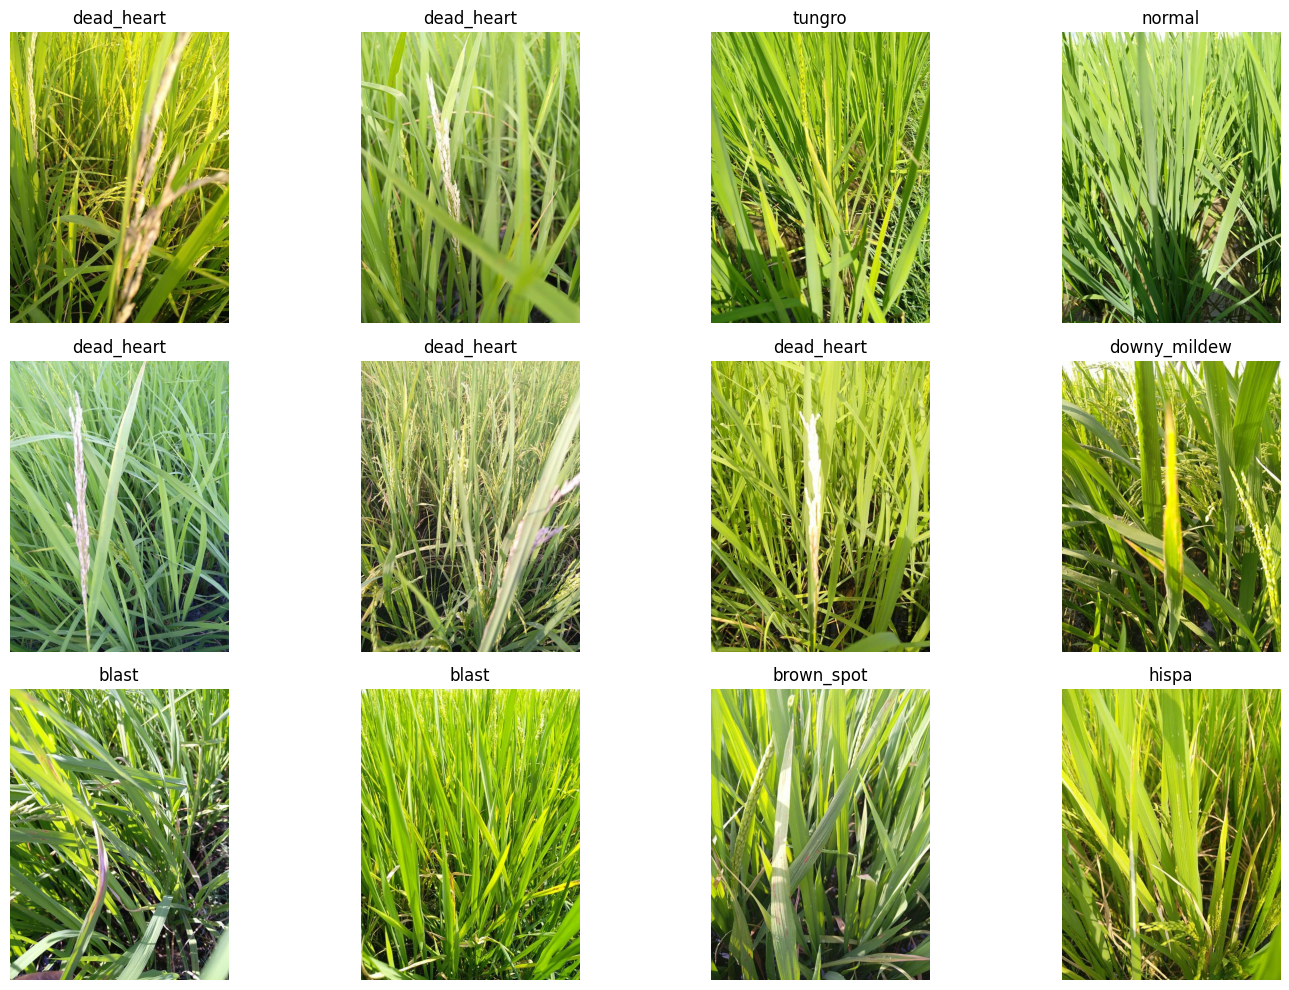

In [10]:

import matplotlib.pyplot as plt
import random

sample_df = df.sample(
    n=min(12, len(df)),
    random_state=42
)

fig, axes = plt.subplots(3, 4, figsize=(15, 10))

for ax, (_, row) in zip(axes.flatten(), sample_df.iterrows()):
    img = Image.open(row["image_path"]).convert("RGB")

    ax.imshow(img)
    ax.set_title(row["label"])
    ax.axis("off")

plt.tight_layout()
plt.show()


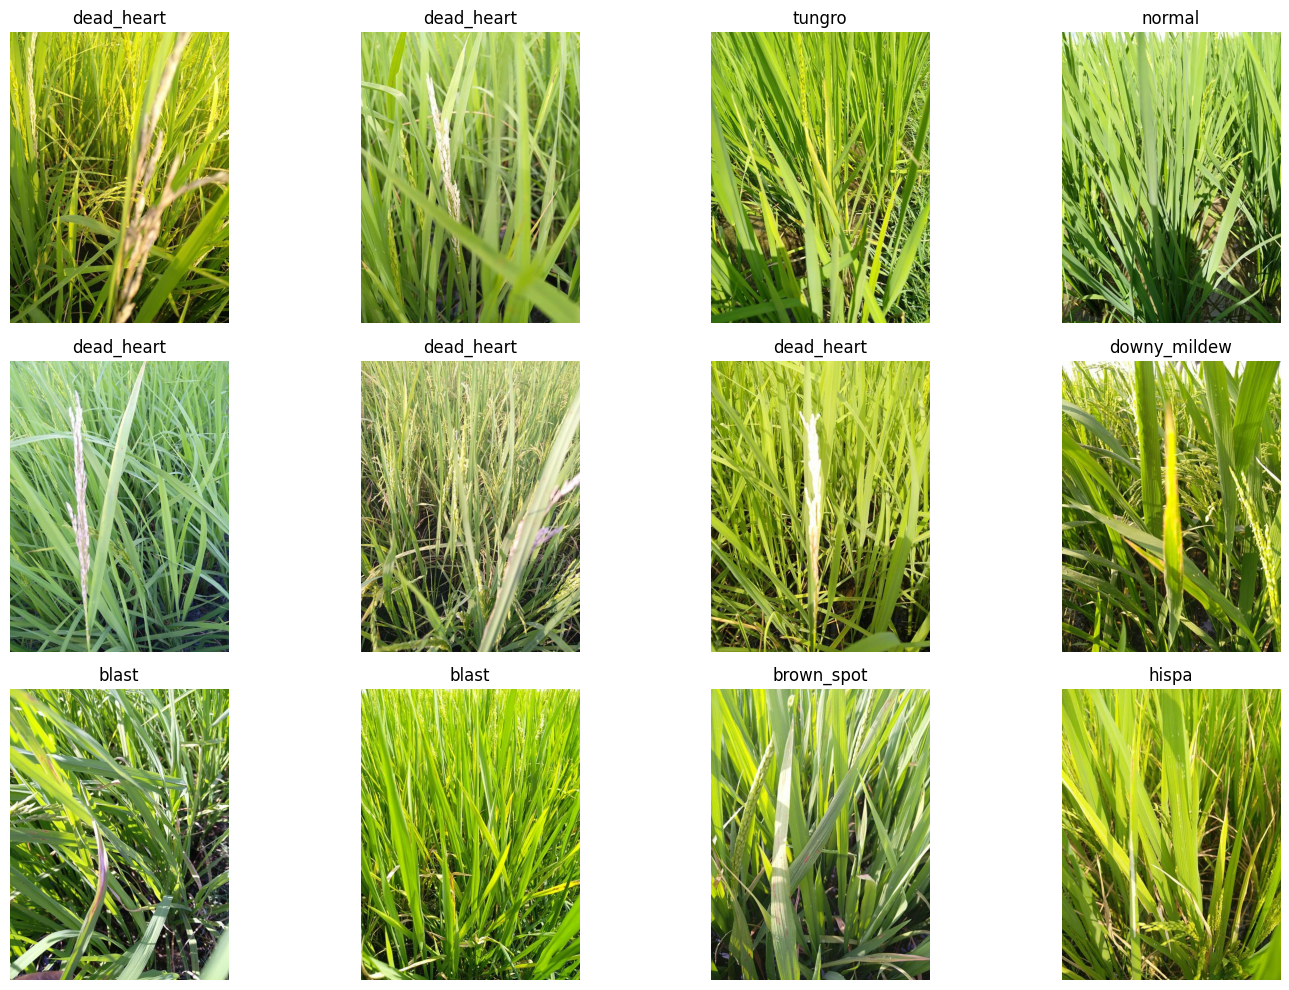

In [11]:

import matplotlib.pyplot as plt
import random

sample_df = df.sample(
    n=min(12, len(df)),
    random_state=42
)

fig, axes = plt.subplots(3, 4, figsize=(15, 10))

for ax, (_, row) in zip(axes.flatten(), sample_df.iterrows()):
    img = Image.open(row["image_path"]).convert("RGB")

    ax.imshow(img)
    ax.set_title(row["label"])
    ax.axis("off")

plt.tight_layout()
plt.show()


Step 1. Create stratified dataset splits

In [12]:

import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42

# Check the validated dataframe
required = {"image", "label", "image_path"}
assert required.issubset(df.columns), (
    f"Missing columns: {required - set(df.columns)}"
)

assert len(df) == 10407, "Unexpected dataset size"
assert df["label"].nunique() == 10, "Expected 10 classes"
assert df["image_path"].notna().all()

# Check duplicate filenames
assert df["image"].is_unique, "Duplicate image filenames detected"

# 15% independent test set
train_val_df, test_df = train_test_split(
    df,
    test_size=0.15,
    random_state=SEED,
    stratify=df["label"]
)

# 15% of total dataset for validation
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=train_val_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Verify no image overlap
assert set(train_df["image"]).isdisjoint(val_df["image"])
assert set(train_df["image"]).isdisjoint(test_df["image"])
assert set(val_df["image"]).isdisjoint(test_df["image"])

print("DATASET SPLIT COMPLETED")
print("-----------------------")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))
print("Image overlap: None")


DATASET SPLIT COMPLETED
-----------------------
Training: 7284
Validation: 1561
Testing: 1562
Total: 10407
Image overlap: None


Step 2. Analyze class distribution

,Training,Validation,Testing
label,,,
bacterial_leaf_blight,335,72,72
bacterial_leaf_streak,266,57,57
bacterial_panicle_blight,236,50,51
blast,1216,261,261
brown_spot,675,145,145
dead_heart,1010,216,216
downy_mildew,434,93,93
hispa,1116,239,239
normal,1234,265,265


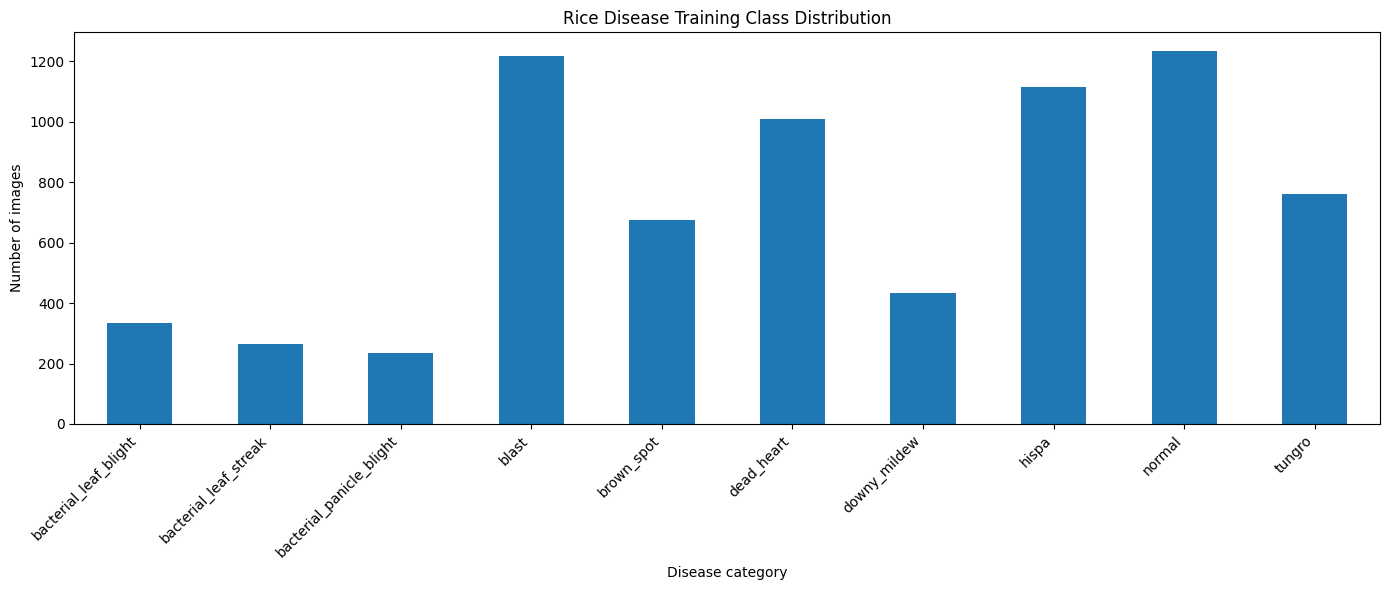

Largest training class: 1234
Smallest training class: 236
Imbalance ratio: 5.23


In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

classes = sorted(df["label"].unique())

class_counts = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
}).reindex(classes)

display(class_counts)

plt.figure(figsize=(14, 6))

class_counts["Training"].plot(kind="bar")

plt.title("Rice Disease Training Class Distribution")
plt.xlabel("Disease category")
plt.ylabel("Number of images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Largest training class:",
      class_counts["Training"].max())

print("Smallest training class:",
      class_counts["Training"].min())

print("Imbalance ratio:",
      round(
          class_counts["Training"].max() /
          class_counts["Training"].min(), 2
      ))


Step 3. Define image preprocessing and augmentation
For Rice-SWAM, we need to distinguish actual disease patterns such as:
- Brown lesions.
- Yellowing and discoloration.
- Leaf streaks.
- Damaged leaf edges.
- Spots and irregular disease regions.
Therefore, augmentation must not distort these characteristics excessively.

Our initial transformations:
Operation	Training	Validation/testing
Resize	224 × 224	224 × 224
Horizontal flip	Yes	No
Small rotation	Yes	No
Color adjustment	Mild	No
Normalization	ImageNet	ImageNet

In [14]:

import torch
from torchvision import transforms

IMAGE_SIZE = 224

# ImageNet normalization for pretrained vision models
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(degrees=10),

    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.10,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Training transformations ready.")
print("Evaluation transformations ready.")
print("Image resolution:", IMAGE_SIZE)


Training transformations ready.
Evaluation transformations ready.
Image resolution: 224


Step 4. Create class-to-index mapping
A neural network requires numerical class labels instead of disease names.

Cell 4 — Label encoding

In [15]:

import json

classes = sorted(df["label"].unique())

class_to_idx = {
    name: index
    for index, name in enumerate(classes)
}

idx_to_class = {
    index: name
    for name, index in class_to_idx.items()
}

print("CLASS MAPPING")

for name, index in class_to_idx.items():
    print(f"{index}: {name}")

# Add numerical labels
for split in [train_df, val_df, test_df]:
    split["target"] = split["label"].map(class_to_idx)

    assert split["target"].notna().all()

    split["target"] = split["target"].astype(int)

assert len(class_to_idx) == 10

print("\nAll class labels encoded successfully.")


CLASS MAPPING
0: bacterial_leaf_blight
1: bacterial_leaf_streak
2: bacterial_panicle_blight
3: blast
4: brown_spot
5: dead_heart
6: downy_mildew
7: hispa
8: normal
9: tungro

All class labels encoded successfully.


Step 5. Implement the custom PyTorch dataset
We will create a custom dataset class that loads rice leaf images and their corresponding disease labels.

This is an important component because the Rice-SWAM model will receive batches of images through this class.

In [16]:

from torch.utils.data import Dataset
from PIL import Image
import os

class RiceDiseaseDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["image_path"]
        label = int(row["target"])

        # Load image safely in RGB format
        image = Image.open(image_path).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, label


train_dataset = RiceDiseaseDataset(
    train_df,
    transform=train_transform
)

val_dataset = RiceDiseaseDataset(
    val_df,
    transform=eval_transform
)

test_dataset = RiceDiseaseDataset(
    test_df,
    transform=eval_transform
)

print("PyTorch datasets created successfully.")

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))


PyTorch datasets created successfully.
Training samples: 7284
Validation samples: 1561
Testing samples: 1562


Step 6. Create PyTorch DataLoaders
The DataLoader sends image batches to the GPU during model training.

For your Kaggle Tesla T4 with approximately 14.56 GB VRAM, we will initially use a batch size of 32.

This is a conservative starting point. We can increase it after checking GPU memory usage.

In [17]:

from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("DATALOADERS CREATED")
print("-------------------")

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))
print("Batch size:", BATCH_SIZE)


DATALOADERS CREATED
-------------------
Training batches: 228
Validation batches: 49
Testing batches: 49
Batch size: 32


Step 7. Test one complete batch on the GPU
Before implementing SWAM, we must verify that the image-loading pipeline works correctly.

In [18]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

images, labels = next(iter(train_loader))

print("GPU device:", device)

print("\nBatch information:")
print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

# Transfer one batch to GPU
images_gpu = images.to(device, non_blocking=True)
labels_gpu = labels.to(device, non_blocking=True)

print("\nGPU verification:")
print("Images device:", images_gpu.device)
print("Labels device:", labels_gpu.device)

print("\nFirst 10 labels:")
print(labels_gpu[:10].cpu().tolist())

assert images.shape[1:] == (3, 224, 224)
assert images_gpu.device.type == "cuda"

print("\nSUCCESS: Rice image batches are ready for GPU training!")


GPU device: cuda

Batch information:
Image shape: torch.Size([32, 3, 224, 224])
Label shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64

GPU verification:
Images device: cuda:0
Labels device: cuda:0

First 10 labels:
[5, 5, 7, 6, 4, 3, 5, 1, 9, 3]

SUCCESS: Rice image batches are ready for GPU training!


Step 8. Visualize preprocessed images
Because normalization changes pixel values, we will reverse normalization for visualization.

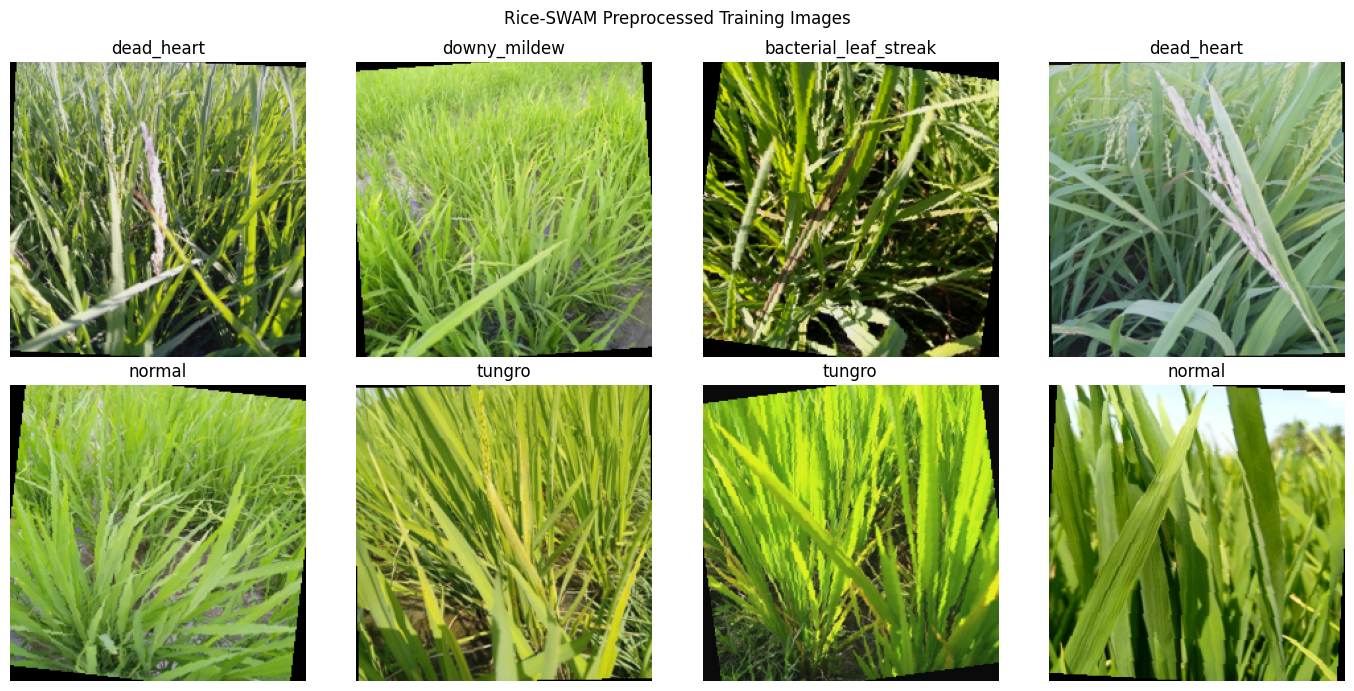

In [19]:

import numpy as np
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flatten()):

    image = images[i].permute(1, 2, 0).numpy()

    # Reverse ImageNet normalization
    mean = np.array(IMAGENET_MEAN)
    std = np.array(IMAGENET_STD)

    image = image * std + mean
    image = np.clip(image, 0, 1)

    class_name = idx_to_class[int(labels[i])]

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("Rice-SWAM Preprocessed Training Images")
plt.tight_layout()
plt.show()


Step 9. Save the prepared dataset and experiment configuration
We need to preserve the splits so that future experiments use exactly the same training, validation and testing images.

In [20]:

import os
import json

OUTPUT_DIR = "/kaggle/working/rice_swam_dataset"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save split CSV files
train_df.to_csv(
    f"{OUTPUT_DIR}/train_split.csv",
    index=False
)

val_df.to_csv(
    f"{OUTPUT_DIR}/validation_split.csv",
    index=False
)

test_df.to_csv(
    f"{OUTPUT_DIR}/test_split.csv",
    index=False
)

# Save class mapping
with open(
    f"{OUTPUT_DIR}/class_mapping.json", "w"
) as file:
    json.dump(class_to_idx, file, indent=4)

# Save experiment configuration
config = {
    "project": "Rice-SWAM",
    "dataset": "Paddy Doctor",
    "total_images": len(df),
    "number_of_classes": len(classes),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "random_seed": SEED,
    "train_images": len(train_df),
    "validation_images": len(val_df),
    "test_images": len(test_df),
    "normalization": "ImageNet",
    "class_mapping": class_to_idx
}

with open(
    f"{OUTPUT_DIR}/dataset_config.json", "w"
) as file:
    json.dump(config, file, indent=4)

print("Rice-SWAM dataset preparation saved!")

for filename in os.listdir(OUTPUT_DIR):
    print("-", filename)


Rice-SWAM dataset preparation saved!
- validation_split.csv
- train_split.csv
- dataset_config.json
- class_mapping.json
- test_split.csv


In [21]:

print("=" * 50)
print("RICE-SWAM DATASET PREPARATION REPORT")
print("=" * 50)

print("Total validated images:", len(df))
print("Number of classes:", len(classes))

print("\nDataset splits:")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

print("\nImage configuration:")
print("Resolution:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of workers:", NUM_WORKERS)

print("\nHardware:")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        ),
        "GB"
    )

print("\nClass mapping:")
for idx, name in idx_to_class.items():
    print(idx, ":", name)

print("\nDataset output:", OUTPUT_DIR)

print("\n" + "=" * 50)
print("DATA PREPARATION PIPELINE COMPLETED")
print("=" * 50)


RICE-SWAM DATASET PREPARATION REPORT
Total validated images: 10407
Number of classes: 10

Dataset splits:
Training: 7284
Validation: 1561
Testing: 1562

Image configuration:
Resolution: 224 x 224
Batch size: 32
Number of workers: 2

Hardware:
Device: cuda
GPU: Tesla T4
VRAM: 14.56 GB

Class mapping:
0 : bacterial_leaf_blight
1 : bacterial_leaf_streak
2 : bacterial_panicle_blight
3 : blast
4 : brown_spot
5 : dead_heart
6 : downy_mildew
7 : hispa
8 : normal
9 : tungro

Dataset output: /kaggle/working/rice_swam_dataset

DATA PREPARATION PIPELINE COMPLETED


*****Step 2: Rice-SWAM architecture development.*****

***Rice-SWAM — Step 2: Baseline model development***
Step 2 objectives

1. Build a pretrained EfficientNet-B0 baseline.
2. Train it on the 10 rice disease categories.
3. Monitor training and validation accuracy.
4. Calculate precision, recall, F1-score and confusion matrix.
5. Save the best-performing model.
6. Use the baseline results to guide the proposed Rice-SWAM architecture.
Baseline configuration
Parameter	Initial setting
Architecture	EfficientNet-B0
Input size	224 × 224
Classes	10
Batch size	32
Optimizer	AdamW
Learning rate	0.0001
Weight decay	0.0001
Epochs	15
Loss	Cross Entropy
Hardware	NVIDIA Tesla T4
Precision	Mixed precision (FP16)


We will use ImageNet-pretrained weights if Kaggle can access them. This gives us a useful transfer-learning baseline.

Create the baseline model

In [22]:

import torch
import torch.nn as nn
import timm

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLASSES = 10

# Create EfficientNet-B0
model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=NUM_CLASSES
)

model = model.to(device)

print("BASELINE MODEL CREATED")
print("-----------------------")
print("Architecture: EfficientNet-B0")
print("Number of classes:", NUM_CLASSES)
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

BASELINE MODEL CREATED
-----------------------
Architecture: EfficientNet-B0
Number of classes: 10
Device: cuda
GPU: Tesla T4
Total parameters: 4,020,358
Trainable parameters: 4,020,358


Configure optimizer and loss function

In [23]:

import torch.optim as optim

EPOCHS = 15
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

# Mixed precision training
scaler = torch.amp.GradScaler("cuda")

print("Optimizer:", optimizer)
print("Loss:", criterion)
print("Scheduler:", scheduler)
print("Mixed precision: Enabled")


Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 0.0001
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)
Loss: CrossEntropyLoss()
Scheduler: <torch.optim.lr_scheduler.CosineAnnealingLR object at 0x7f216b90b230>
Mixed precision: Enabled


*Implement the training and validation functions*
We will use validation loss and macro F1-score to monitor performance. Macro F1 gives equal importance to each disease class, which is useful if the dataset is imbalanced.

In [24]:

from sklearn.metrics import f1_score
from tqdm.auto import tqdm

def train_one_epoch(model, loader, optimizer, criterion, scaler, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(loader, desc="Training", leave=False):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


@torch.no_grad()
def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    for images, labels in tqdm(loader, desc="Validation", leave=False):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    epoch_loss = running_loss / len(loader.dataset)

    accuracy = sum(
        p == y for p, y in zip(all_predictions, all_labels)
    ) / len(all_labels)

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, accuracy, macro_f1


Train EfficientNet-B0
We will save the checkpoint with the best validation macro F1-score.

In [25]:

import copy
import os
import pandas as pd

SAVE_DIR = "/kaggle/working/rice_swam_models"
os.makedirs(SAVE_DIR, exist_ok=True)

best_f1 = -1.0
best_epoch = 0

history = []

best_model_state = None

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print("-" * 40)

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        scaler,
        device
    )

    val_loss, val_acc, val_f1 = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step()

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "learning_rate": current_lr
    })

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Validation Macro F1: {val_f1:.4f}")
    print(f"Learning Rate: {current_lr:.7f}")

    if val_f1 > best_f1:

        best_f1 = val_f1
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(model.state_dict())

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": best_model_state,
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_macro_f1": best_f1,
            "class_to_idx": class_to_idx,
            "architecture": "efficientnet_b0"
        }, f"{SAVE_DIR}/efficientnet_b0_best.pth")

        print("Best model checkpoint saved!")

    print("-" * 40)

history_df = pd.DataFrame(history)

history_df.to_csv(
    f"{SAVE_DIR}/efficientnet_training_history.csv",
    index=False
)

print("\nTRAINING COMPLETED")
print("Best epoch:", best_epoch)
print("Best validation macro F1:", best_f1)



Epoch 1/15
----------------------------------------


Training:   0%|          | 0/228 [00:00<?, ?it/s]

Validation:   0%|          | 0/49 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f222de21a80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f222de21a80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Train Loss: 1.5825
Train Accuracy: 0.5402
Validation Loss: 0.7031
Validation Accuracy: 0.7777
Validation Macro F1: 0.7441
Learning Rate: 0.0000989
Best model checkpoint saved!
----------------------------------------

Epoch 2/15
----------------------------------------


Training:   0%|          | 0/228 [00:00<?, ?it/s]

... (40 outputs left out)

Train Loss: 0.0212
Train Accuracy: 0.9942
Validation Loss: 0.1468
Validation Accuracy: 0.9648
Validation Macro F1: 0.9660
Learning Rate: 0.0000011
----------------------------------------

Epoch 15/15
----------------------------------------


Training:   0%|          | 0/228 [00:00<?, ?it/s]

Validation:   0%|          | 0/49 [00:00<?, ?it/s]

Train Loss: 0.0223
Train Accuracy: 0.9945
Validation Loss: 0.1478
Validation Accuracy: 0.9635
Validation Macro F1: 0.9656
Learning Rate: 0.0000000
----------------------------------------

TRAINING COMPLETED
Best epoch: 11
Best validation macro F1: 0.9662987904998781


Visualize training performance

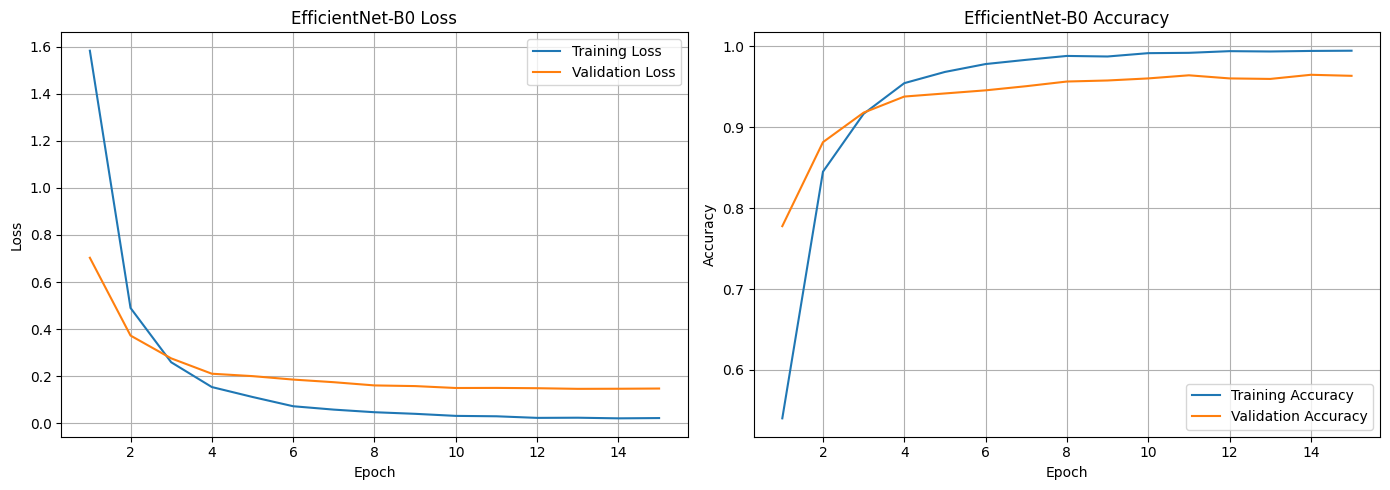

In [26]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training Loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("EfficientNet-B0 Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy curves
axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Training Accuracy"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title("EfficientNet-B0 Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


Look for:
- Training loss decreasing.
- Validation loss generally decreasing.
- Training and validation accuracy improving.
- A large gap between training and validation performance, which could indicate overfitting.
7. Evaluate the baseline model
We will now load the best checkpoint and evaluate it on the independent test set.

Do not use test results to adjust hyperparameters or choose architecture components.

In [27]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)
import numpy as np

checkpoint = torch.load(
    f"{SAVE_DIR}/efficientnet_b0_best.pth",
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():

    for images, labels in tqdm(test_loader, desc="Testing"):

        images = images.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_targets.extend(labels.tolist())

test_accuracy = accuracy_score(
    all_targets,
    all_predictions
)

test_macro_f1 = f1_score(
    all_targets,
    all_predictions,
    average="macro"
)

print("BASELINE TEST RESULTS")
print("---------------------")
print("Test accuracy:", round(test_accuracy, 4))
print("Test macro F1:", round(test_macro_f1, 4))

print("\nClassification Report:\n")

print(classification_report(
    all_targets,
    all_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=[idx_to_class[i] for i in range(NUM_CLASSES)],
    zero_division=0
))


Testing:   0%|          | 0/49 [00:00<?, ?it/s]

BASELINE TEST RESULTS
---------------------
Test accuracy: 0.9597
Test macro F1: 0.9552

Classification Report:

                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.95      0.97      0.96        72
   bacterial_leaf_streak       0.98      0.95      0.96        57
bacterial_panicle_blight       0.98      0.94      0.96        51
                   blast       0.96      0.98      0.97       261
              brown_spot       0.94      0.92      0.93       145
              dead_heart       0.99      0.99      0.99       216
            downy_mildew       0.94      0.88      0.91        93
                   hispa       0.96      0.96      0.96       239
                  normal       0.96      0.98      0.97       265
                  tungro       0.94      0.93      0.94       163

                accuracy                           0.96      1562
               macro avg       0.96      0.95      0.96      1562
            weighted avg   

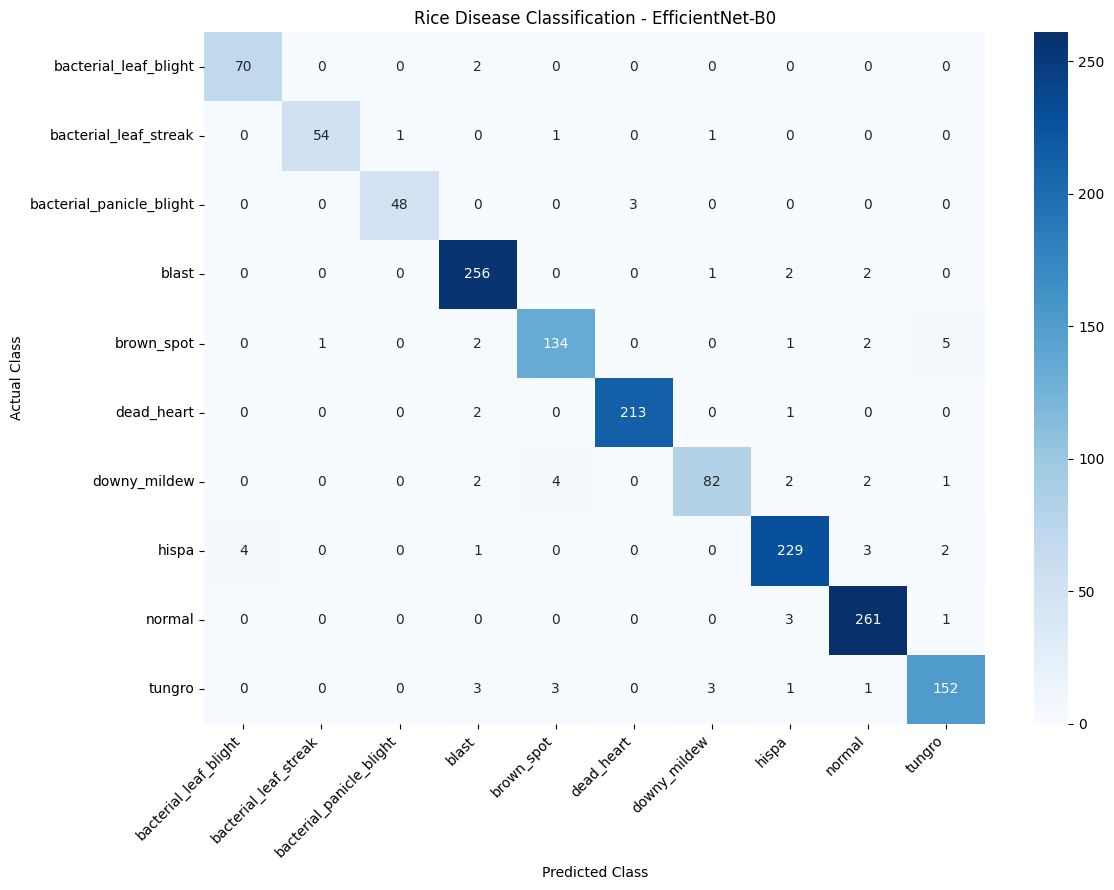

In [28]:

import seaborn as sns

cm = confusion_matrix(
    all_targets,
    all_predictions,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[idx_to_class[i] for i in range(NUM_CLASSES)],
    yticklabels=[idx_to_class[i] for i in range(NUM_CLASSES)]
)

plt.title("Rice Disease Classification - EfficientNet-B0")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


Save baseline experiment results

In [29]:

baseline_results = {
    "model": "EfficientNet-B0",
    "dataset": "Paddy Doctor",
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1),
    "best_validation_macro_f1": float(best_f1),
    "best_epoch": int(best_epoch),
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "image_size": IMAGE_SIZE,
    "seed": SEED
}

import json

with open(
    f"{SAVE_DIR}/baseline_results.json",
    "w"
) as f:
    json.dump(baseline_results, f, indent=4)

print("Baseline experiment results saved.")

print("\nSaved model files:")
for file in os.listdir(SAVE_DIR):
    print("-", file)


Baseline experiment results saved.

Saved model files:
- baseline_results.json
- efficientnet_b0_best.pth
- efficientnet_training_history.csv


***Proposed Rice-SWAM architecture***

Implement Saliency-Weighted Asymmetric Merging

In [30]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import math


class SaliencyWeightedAsymmetricMerging(nn.Module):

    def __init__(self, embed_dim, keep_ratio=0.75):
        super().__init__()

        self.keep_ratio = keep_ratio

        # Learnable token saliency predictor
        self.saliency_predictor = nn.Linear(embed_dim, 1)

    def forward(self, tokens):

        # tokens: [Batch, Number of patches, Embedding dimension]

        B, N, C = tokens.shape

        if N < 2:
            raise ValueError("SWAM requires at least two patch tokens.")

        # Step 1: Estimate token saliency
        saliency = torch.sigmoid(
            self.saliency_predictor(tokens)
        ).squeeze(-1)

        # Step 2: Select salient anchor tokens
        keep_count = max(
            1,
            min(N - 1, math.ceil(N * self.keep_ratio))
        )

        keep_indices = torch.topk(
            saliency,
            k=keep_count,
            dim=1,
            sorted=True
        ).indices

        # Identify discarded tokens
        discarded_mask = torch.ones(
            B, N, dtype=torch.bool, device=tokens.device
        )

        discarded_mask.scatter_(1, keep_indices, False)

        discarded_indices = torch.arange(
            N, device=tokens.device
        ).unsqueeze(0).expand(B, -1)

        discarded_indices = discarded_indices[
            discarded_mask
        ].reshape(B, N - keep_count)

        # Gather anchor and discarded features
        anchors = torch.gather(
            tokens,
            1,
            keep_indices.unsqueeze(-1).expand(-1, -1, C)
        )

        discarded = torch.gather(
            tokens,
            1,
            discarded_indices.unsqueeze(-1).expand(-1, -1, C)
        )

        anchor_saliency = torch.gather(
            saliency, 1, keep_indices
        )

        discarded_saliency = torch.gather(
            saliency, 1, discarded_indices
        )

        # Step 3: Calculate cosine similarity
        normalized_anchors = F.normalize(anchors, dim=-1)
        normalized_discarded = F.normalize(discarded, dim=-1)

        similarity = torch.bmm(
            normalized_discarded,
            normalized_anchors.transpose(1, 2)
        )

        # Assign each discarded token to its closest anchor
        best_similarity, assignments = similarity.max(dim=-1)

        # Step 4: Saliency-weighted asymmetric merging
        merge_weights = (
            (1.0 - discarded_saliency)
            * best_similarity.clamp(min=0.0)
        )

        weighted_anchors = (
            anchors * anchor_saliency.unsqueeze(-1)
        )

        weighted_sum = weighted_anchors.clone()

        denominator = anchor_saliency.clone()

        weighted_sum.scatter_add_(
            1,
            assignments.unsqueeze(-1).expand(-1, -1, C),
            discarded * merge_weights.unsqueeze(-1)
        )

        denominator.scatter_add_(
            1,
            assignments,
            merge_weights
        )

        merged_tokens = weighted_sum / (
            denominator.unsqueeze(-1) + 1e-8
        )

        return merged_tokens, keep_indices, saliency


Test the proposed SWAM module

In [31]:

# Initialize SWAM
embed_dim = 192

swam = SaliencyWeightedAsymmetricMerging(
    embed_dim=embed_dim,
    keep_ratio=0.75
).to(device)

# Simulate transformer patch tokens
dummy_tokens = torch.randn(
    4, 196, embed_dim,
    device=device,
    requires_grad=True
)

# Forward pass
merged_tokens, kept_indices, scores = swam(dummy_tokens)

print("SWAM MODULE TEST")
print("----------------")

print("Input shape:", dummy_tokens.shape)
print("Output shape:", merged_tokens.shape)
print("Retained indices:", kept_indices.shape)
print("Saliency scores:", scores.shape)

# Check output dimensions
assert merged_tokens.shape == (4, 147, 192)
assert kept_indices.shape == (4, 147)
assert scores.shape == (4, 196)

# Backward pass
loss = merged_tokens.square().mean()
loss.backward()

assert swam.saliency_predictor.weight.grad is not None
assert torch.isfinite(
    swam.saliency_predictor.weight.grad
).all()

print("\nForward pass successful.")
print("Backward pass successful.")
print("Saliency predictor receives gradients.")
print("SWAM module is operational!")


SWAM MODULE TEST
----------------
Input shape: torch.Size([4, 196, 192])
Output shape: torch.Size([4, 147, 192])
Retained indices: torch.Size([4, 147])
Saliency scores: torch.Size([4, 196])

Forward pass successful.
Backward pass successful.
Saliency predictor receives gradients.
SWAM module is operational!


Prepare a standard Vision Transformer baseline
We need a standard transformer baseline before claiming SWAM improvements.

Kaggle Cell 3 — Create ViT-Tiny

In [32]:

import timm
import torch.nn as nn

vit_baseline = timm.create_model(
    "vit_tiny_patch16_224",
    pretrained=True,
    num_classes=10
)

vit_baseline = vit_baseline.to(device)

print("Vision Transformer baseline created.")

print("Architecture: ViT-Tiny/16")
print("Number of classes:", 10)

total_params = sum(
    p.numel() for p in vit_baseline.parameters()
)

print("Total parameters:", f"{total_params:,}")

print("Device:", device)


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Vision Transformer baseline created.
Architecture: ViT-Tiny/16
Number of classes: 10
Total parameters: 5,526,346
Device: cuda


Experimental plan for validating SWAM
We will conduct controlled experiments rather than rely on one accuracy result.
Experiment	Model	Token merging
E1	EfficientNet-B0	None
E2	ViT-Tiny	None
E3	ViT-Tiny + uniform merging	Uniform
E4	ViT-Tiny + similarity merging	Similarity
E5	ViT-Tiny + proposed SWAM	Saliency-weighted asymmetric

We will measure:
- Test accuracy and macro F1-score.
- Number of retained tokens.
- Number of model parameters.
- FLOPs or MACs.
- GPU inference latency.
- Peak GPU memory usage.
We should also test different retention ratios: 90%, 75%, and 50%.

This will help determine whether SWAM offers a meaningful efficiency-versus-accuracy trade-off.

Important: Our current module is a research prototype. The next implementation step will integrate it into the ViT transformer blocks, preserve the class token and positional information, and test the complete model end-to-end.

Integration strategy
We will use the following design:
- Backbone: pretrained ViT-Tiny/16.
- Embedding dimension: 192.
- Original patch tokens: 196.
- Class token: preserved separately.
- SWAM insertion point: after transformer block 6.
- Token retention ratio: 75%.
- Remaining patch tokens: 147.
- Classification output: 10 rice disease classes.
Why insert SWAM after block 6?

The initial transformer blocks can learn useful visual features before token merging begins. The remaining blocks can then process the compressed representation.

This is a research hypothesis, not a proven optimal insertion point. Later we will compare insertion after blocks 3, 6 and 9.

Create the integrated Rice-SWAM model
Use a new Kaggle notebook cell.

This implementation reuses your pretrained ViT-Tiny backbone and inserts the previously tested SWAM module after the sixth transformer block.

In [33]:

import torch
import torch.nn as nn
import timm
import copy


class RiceSWAM(nn.Module):

    def __init__(
        self,
        backbone,
        num_classes=10,
        keep_ratio=0.75,
        merge_after_block=5
    ):
        super().__init__()

        self.backbone = backbone

        self.embed_dim = backbone.num_features
        self.num_classes = num_classes

        # Number of prefix tokens (normally one CLS token)
        self.num_prefix_tokens = backbone.num_prefix_tokens

        self.merge_after_block = merge_after_block

        # Agriculture-specific SWAM component
        self.swam = SaliencyWeightedAsymmetricMerging(
            embed_dim=self.embed_dim,
            keep_ratio=keep_ratio
        )

        # Replace classification head
        self.backbone.reset_classifier(num_classes)

    def forward(self, images):

        # Patch embedding
        x = self.backbone.patch_embed(images)

        # Add class token and positional embeddings
        x = self.backbone._pos_embed(x)

        # Standard ViT preprocessing
        x = self.backbone.patch_drop(x)
        x = self.backbone.norm_pre(x)

        # Transformer blocks with SWAM integration
        for block_index, block in enumerate(
            self.backbone.blocks
        ):

            x = block(x)

            if block_index == self.merge_after_block:

                # Preserve class token and other prefix tokens
                prefix_tokens = x[:, :self.num_prefix_tokens]

                # Extract only patch tokens
                patch_tokens = x[:, self.num_prefix_tokens:]

                # Apply SWAM to patch tokens
                merged_tokens, kept_indices, saliency = self.swam(
                    patch_tokens
                )

                # Recombine prefix and merged patch tokens
                x = torch.cat(
                    [prefix_tokens, merged_tokens],
                    dim=1
                )

        # Final normalization
        x = self.backbone.norm(x)

        # Classification head
        output = self.backbone.forward_head(x)

        return output


Initialize Rice-SWAM with pretrained ViT weights

In [34]:

# Copy the pretrained ViT baseline
pretrained_backbone = copy.deepcopy(vit_baseline)

# Initialize complete Rice-SWAM architecture
rice_swam = RiceSWAM(
    backbone=pretrained_backbone,
    num_classes=10,
    keep_ratio=0.75,
    merge_after_block=5
)

rice_swam = rice_swam.to(device)

# Count parameters
total_params = sum(
    p.numel() for p in rice_swam.parameters()
)

trainable_params = sum(
    p.numel()
    for p in rice_swam.parameters()
    if p.requires_grad
)

print("RICE-SWAM MODEL INITIALIZED")
print("---------------------------")

print("Architecture: ViT-Tiny + SWAM")
print("Embedding dimension:", rice_swam.embed_dim)
print("Transformer blocks:", len(rice_swam.backbone.blocks))
print("SWAM insertion block:", 6)
print("Token retention:", 75)
print("Number of classes:", 10)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

print("Device:", device)


RICE-SWAM MODEL INITIALIZED
---------------------------
Architecture: ViT-Tiny + SWAM
Embedding dimension: 192
Transformer blocks: 12
SWAM insertion block: 6
Token retention: 75
Number of classes: 10
Total parameters: 5,526,539
Trainable parameters: 5,526,539
Device: cuda


Verify the integrated architecture
Before training, we must check:
1. The input reaches the transformer.
2. SWAM reduces the patch token count.
3. The class token is preserved.
4. The classifier produces 10 outputs.
5. Gradients flow through SWAM and the transformer.

In [35]:

rice_swam.train()

# Obtain one actual training batch
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

# Forward pass
outputs = rice_swam(images)

print("INTEGRATED MODEL TEST")
print("---------------------")

print("Input images:", images.shape)
print("Classification output:", outputs.shape)

# Verify expected classification shape
assert outputs.shape == (images.shape[0], 10)

# Verify SWAM token reduction
assert rice_swam.swam.keep_ratio == 0.75

# Backward test
criterion = nn.CrossEntropyLoss()

loss = criterion(outputs, labels)

rice_swam.zero_grad(set_to_none=True)
loss.backward()

# Check SWAM gradient
swam_gradient = (
    rice_swam.swam.saliency_predictor.weight.grad
)

assert swam_gradient is not None
assert torch.isfinite(swam_gradient).all()

# Check transformer gradient
transformer_gradient = (
    rice_swam.backbone.blocks[0]
    .attn.qkv.weight.grad
)

assert transformer_gradient is not None
assert torch.isfinite(transformer_gradient).all()

print("Loss:", loss.item())
print("SWAM gradient: Available")
print("Transformer gradient: Available")
print("Classification output: Valid")

print("\nRice-SWAM integration successful!")


INTEGRATED MODEL TEST
---------------------
Input images: torch.Size([32, 3, 224, 224])
Classification output: torch.Size([32, 10])
Loss: 4.722074508666992
SWAM gradient: Available
Transformer gradient: Available
Classification output: Valid

Rice-SWAM integration successful!


Train the integrated Rice-SWAM model
Once Cell 3 passes, we can train the full model.

For the first experiment, keep the same experimental settings as our baseline:
- 15 epochs.
- Batch size 32.
- AdamW optimizer.
- Learning rate \(10^{-4}\).
- Cosine learning-rate scheduler.
- Mixed-precision FP16 training.

In [36]:

import torch.optim as optim
import os

EPOCHS_SWAM = 15
LR_SWAM = 1e-4
WEIGHT_DECAY_SWAM = 1e-4

swam_criterion = nn.CrossEntropyLoss()

swam_optimizer = optim.AdamW(
    rice_swam.parameters(),
    lr=LR_SWAM,
    weight_decay=WEIGHT_DECAY_SWAM
)

swam_scheduler = optim.lr_scheduler.CosineAnnealingLR(
    swam_optimizer,
    T_max=EPOCHS_SWAM
)

swam_scaler = torch.amp.GradScaler("cuda")

SWAM_SAVE_DIR = "/kaggle/working/rice_swam_models"

os.makedirs(SWAM_SAVE_DIR, exist_ok=True)

print("Rice-SWAM training configuration ready.")


Rice-SWAM training configuration ready.


In [37]:

import copy
import pandas as pd

best_swam_f1 = -1.0
best_swam_epoch = 0

swam_history = []

best_swam_state = None

for epoch in range(EPOCHS_SWAM):

    print(f"\nRice-SWAM Epoch {epoch + 1}/{EPOCHS_SWAM}")
    print("=" * 50)

    train_loss, train_acc = train_one_epoch(
        rice_swam,
        train_loader,
        swam_optimizer,
        swam_criterion,
        swam_scaler,
        device
    )

    val_loss, val_acc, val_f1 = validate_one_epoch(
        rice_swam,
        val_loader,
        swam_criterion,
        device
    )

    swam_scheduler.step()

    current_lr = swam_optimizer.param_groups[0]["lr"]

    swam_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "learning_rate": current_lr
    })

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Validation Macro F1: {val_f1:.4f}")

    if val_f1 > best_swam_f1:

        best_swam_f1 = val_f1
        best_swam_epoch = epoch + 1

        best_swam_state = copy.deepcopy(
            rice_swam.state_dict()
        )

        torch.save({
            "epoch": best_swam_epoch,
            "model_state_dict": best_swam_state,
            "optimizer_state_dict": swam_optimizer.state_dict(),
            "best_val_macro_f1": best_swam_f1,
            "class_to_idx": class_to_idx,
            "architecture": "Rice-SWAM-ViT-Tiny",
            "keep_ratio": 0.75,
            "merge_after_block": 5
        }, f"{SWAM_SAVE_DIR}/rice_swam_best.pth")

        print("Best Rice-SWAM checkpoint saved!")

swam_history_df = pd.DataFrame(swam_history)

swam_history_df.to_csv(
    f"{SWAM_SAVE_DIR}/rice_swam_training_history.csv",
    index=False
)

print("\nRICE-SWAM TRAINING COMPLETED")
print("Best epoch:", best_swam_epoch)
print("Best validation macro F1:", best_swam_f1)



Rice-SWAM Epoch 1/15


Training:   0%|          | 0/228 [00:00<?, ?it/s]

Validation:   0%|          | 0/49 [00:00<?, ?it/s]

Train Loss: 1.4535
Train Accuracy: 0.5221
Validation Loss: 0.7648
Validation Accuracy: 0.7425
Validation Macro F1: 0.6798
Best Rice-SWAM checkpoint saved!

Rice-SWAM Epoch 2/15


Training:   0%|          | 0/228 [00:00<?, ?it/s]

Validation:   0%|          | 0/49 [00:00<?, ?it/s]

... (41 outputs left out)

Training:   0%|          | 0/228 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f222de21a80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f222de21a80>
Exception ignored in: Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7f222de21a80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/u

Validation:   0%|          | 0/49 [00:00<?, ?it/s]

Train Loss: 0.0131
Train Accuracy: 0.9952
Validation Loss: 0.1064
Validation Accuracy: 0.9731
Validation Macro F1: 0.9712
Best Rice-SWAM checkpoint saved!

RICE-SWAM TRAINING COMPLETED
Best epoch: 15
Best validation macro F1: 0.9711787710410889


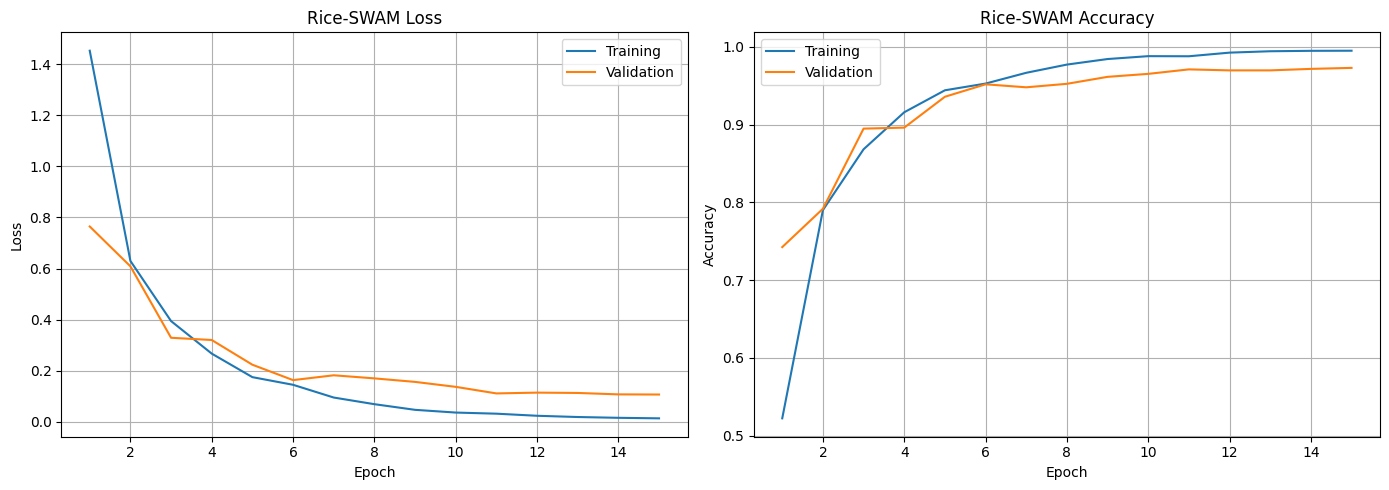

In [38]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    swam_history_df["epoch"],
    swam_history_df["train_loss"],
    label="Training"
)

axes[0].plot(
    swam_history_df["epoch"],
    swam_history_df["val_loss"],
    label="Validation"
)

axes[0].set_title("Rice-SWAM Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    swam_history_df["epoch"],
    swam_history_df["train_accuracy"],
    label="Training"
)

axes[1].plot(
    swam_history_df["epoch"],
    swam_history_df["val_accuracy"],
    label="Validation"
)

axes[1].set_title("Rice-SWAM Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [39]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

checkpoint = torch.load(
    f"{SWAM_SAVE_DIR}/rice_swam_best.pth",
    map_location=device,
    weights_only=False
)

rice_swam.load_state_dict(
    checkpoint["model_state_dict"]
)

rice_swam.eval()

all_predictions = []
all_targets = []

with torch.no_grad():

    for images, labels in tqdm(test_loader, desc="Rice-SWAM testing"):

        images = images.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = rice_swam(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_targets.extend(labels.tolist())

swam_test_accuracy = accuracy_score(
    all_targets,
    all_predictions
)

swam_test_f1 = f1_score(
    all_targets,
    all_predictions,
    average="macro"
)

print("RICE-SWAM TEST RESULTS")
print("----------------------")
print("Test accuracy:", round(swam_test_accuracy, 4))
print("Test macro F1:", round(swam_test_f1, 4))

print("\nClassification Report:")

print(classification_report(
    all_targets,
    all_predictions,
    labels=list(range(10)),
    target_names=[idx_to_class[i] for i in range(10)],
    zero_division=0
))


Rice-SWAM testing:   0%|          | 0/49 [00:00<?, ?it/s]

RICE-SWAM TEST RESULTS
----------------------
Test accuracy: 0.968
Test macro F1: 0.9663

Classification Report:
                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.92      1.00      0.96        72
   bacterial_leaf_streak       0.98      0.98      0.98        57
bacterial_panicle_blight       1.00      0.98      0.99        51
                   blast       0.96      0.98      0.97       261
              brown_spot       0.99      0.94      0.96       145
              dead_heart       0.99      1.00      0.99       216
            downy_mildew       0.93      0.89      0.91        93
                   hispa       0.94      0.97      0.95       239
                  normal       0.99      0.98      0.98       265
                  tungro       0.96      0.94      0.95       163

                accuracy                           0.97      1562
               macro avg       0.97      0.97      0.97      1562
            weighted avg   

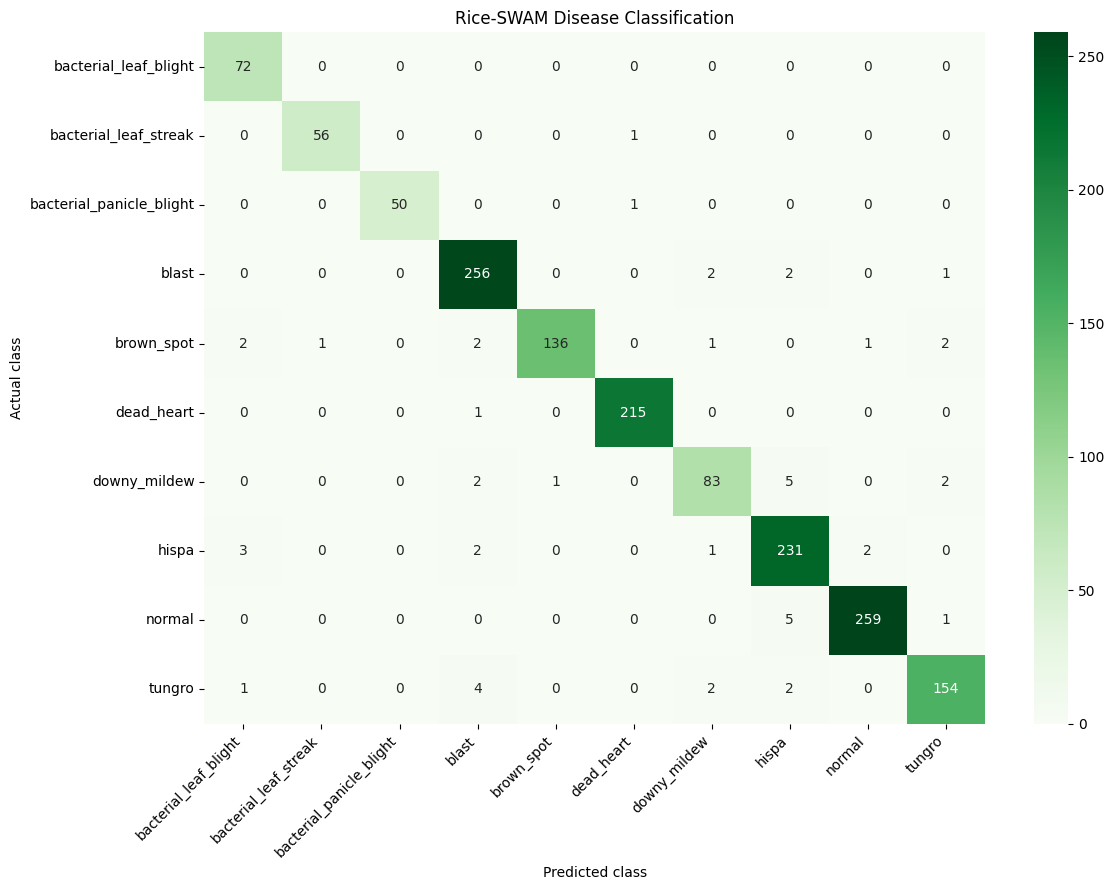

In [40]:

import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_targets,
    all_predictions,
    labels=list(range(10))
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=[idx_to_class[i] for i in range(10)],
    yticklabels=[idx_to_class[i] for i in range(10)]
)

plt.title("Rice-SWAM Disease Classification")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Controlled experiments and ablation study
Your current results are:
Model	Test accuracy	Test macro F1
EfficientNet-B0	96.22%	95.31%
Rice-SWAM (ViT-Tiny)	95.65%	95.15%
Difference (SWAM − EfficientNet)	−0.57 pp	−0.16 pp

In [41]:

import timm
import torch
import torch.nn as nn
import torch.optim as optim
import copy
import os
import numpy as np

from sklearn.metrics import accuracy_score, f1_score

# Create a standard ViT-Tiny baseline (without SWAM)
vit_standard = timm.create_model(
    "vit_tiny_patch16_224",
    pretrained=True,
    num_classes=10
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    vit_standard.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=15
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

os.makedirs("/kaggle/working/rice_swam_models", exist_ok=True)

best_val_f1 = 0.0
best_vit_path = "/kaggle/working/rice_swam_models/vit_tiny_baseline_best.pth"

history_vit = []

for epoch in range(15):

    # Training
    vit_standard.train()
    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = vit_standard(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_total += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_total / train_total
    train_accuracy = train_correct / train_total

    # Validation
    vit_standard.eval()
    val_predictions = []
    val_targets = []
    val_loss_total = 0.0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                outputs = vit_standard(images)
                loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)
            val_total += labels.size(0)

            val_predictions.extend(outputs.argmax(1).cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    val_loss = val_loss_total / val_total
    val_accuracy = accuracy_score(val_targets, val_predictions)
    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro"
    )

    scheduler.step()

    history_vit.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1
    })

    print(
        f"Epoch {epoch+1:02d}/15 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        torch.save(vit_standard.state_dict(), best_vit_path)
        print("Best ViT-Tiny checkpoint saved.")

print("\nStandard ViT-Tiny training completed.")
print("Best validation macro F1:", best_val_f1)
print("Checkpoint:", best_vit_path)


Epoch 01/15 | Train Loss: 1.3185 | Train Acc: 0.5482 | Val Loss: 0.7657 | Val Acc: 0.7450 | Val Macro F1: 0.7023
Best ViT-Tiny checkpoint saved.
Epoch 02/15 | Train Loss: 0.5623 | Train Acc: 0.8178 | Val Loss: 0.4472 | Val Acc: 0.8539 | Val Macro F1: 0.8416
Best ViT-Tiny checkpoint saved.
Epoch 03/15 | Train Loss: 0.3089 | Train Acc: 0.8966 | Val Loss: 0.2764 | Val Acc: 0.9135 | Val Macro F1: 0.9057
Best ViT-Tiny checkpoint saved.
Epoch 04/15 | Train Loss: 0.2075 | Train Acc: 0.9304 | Val Loss: 0.2390 | Val Acc: 0.9238 | Val Macro F1: 0.9162
Best ViT-Tiny checkpoint saved.
Epoch 05/15 | Train Loss: 0.1412 | Train Acc: 0.9544 | Val Loss: 0.2207 | Val Acc: 0.9321 | Val Macro F1: 0.9277
Best ViT-Tiny checkpoint saved.
Epoch 06/15 | Train Loss: 0.1043 | Train Acc: 0.9655 | Val Loss: 0.2327 | Val Acc: 0.9218 | Val Macro F1: 0.9084
Epoch 07/15 | Train Loss: 0.0726 | Train Acc: 0.9773 | Val Loss: 0.1912 | Val Acc: 0.9488 | Val Macro F1: 0.9424
Best ViT-Tiny checkpoint saved.
Epoch 08/15 | Tra